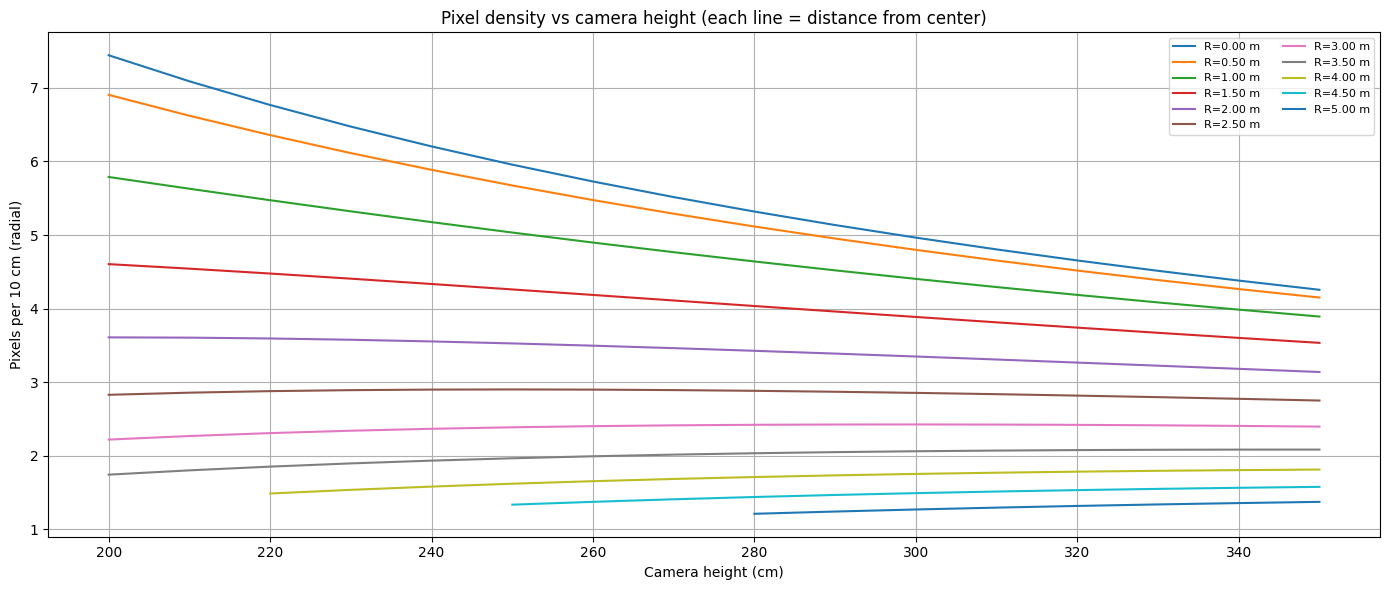

In [7]:
import math
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------
# Geometry helper
# ----------------------------
@dataclass
class Point:
    x: float
    y: float

# ----------------------------
# Your calibration + fisheye model (as-is)
# ----------------------------
MAX_UNDISTORT_ITRS = 10

class CameraCalibrationParameters:
    def __init__(self, cx, cy, fx, fy, k0, k1, k2, k3):
        self.CX = float(cx)
        self.CY = float(cy)
        self.FX = float(fx)
        self.FY = float(fy)
        self.K0 = float(k0)
        self.K1 = float(k1)
        self.K2 = float(k2)
        self.K3 = float(k3)
        self.FX_INV = 1.0 / self.FX
        self.FY_INV = 1.0 / self.FY
        self.EPS2 = min(self.FX_INV, self.FY_INV) ** 2

class FisheyeInternal:
    @staticmethod
    def normalize(point_in, params):
        return Point((point_in.x - params.CX) * params.FX_INV,
                     (point_in.y - params.CY) * params.FY_INV)

    @staticmethod
    def denormalize(point_in, params):
        return Point(point_in.x * params.FX + params.CX,
                     point_in.y * params.FY + params.CY)

    @staticmethod
    def distort_normalized(point_in, params):
        r2 = point_in.x**2 + point_in.y**2
        if r2 < params.EPS2:
            return Point(point_in.x, point_in.y)

        r = math.sqrt(r2)
        t = math.atan(r)
        t2 = t * t
        t3 = t2 * t
        t5 = t3 * t2
        t7 = t5 * t2

        a = (t + params.K0 * t3 + params.K1 * t5 + params.K2 * t7 + params.K3 * t7 * t2) / r
        return Point(point_in.x * a, point_in.y * a)

def distort(point_in, params):
    p = FisheyeInternal.normalize(point_in, params)
    p = FisheyeInternal.distort_normalized(p, params)
    return FisheyeInternal.denormalize(p, params)

def undistort(point_in, params):
    p = FisheyeInternal.normalize(point_in, params)
    guess = Point(p.x, p.y)
    for _ in range(MAX_UNDISTORT_ITRS):
        d = FisheyeInternal.distort_normalized(guess, params)
        dx = p.x - d.x
        dy = p.y - d.y
        guess.x += dx
        guess.y += dy
        if dx*dx + dy*dy < params.EPS2:
            break
    return FisheyeInternal.denormalize(guess, params)

def cm2pixel(point_in_cm, cam_height_cm, height_cm, params):
    # point_in_cm is in cm on ground plane coordinate system (x right, y up),
    # camera at (0,0,cam_height_cm), looking down.
    point_out = Point(point_in_cm.x, point_in_cm.y)
    if height_cm != 0:
        factor = cam_height_cm / (cam_height_cm - height_cm)
        point_out.x *= factor
        point_out.y *= factor

    cam_height_inv = 1.0 / cam_height_cm
    px = point_out.x * params.FX * cam_height_inv + params.CX
    py = -point_out.y * params.FY * cam_height_inv + params.CY
    return distort(Point(px, py), params)

# ----------------------------
# Pixel density computation
# ----------------------------
def pixel_density_per_10cm(cam_height_cm, radius_cm, params,
                           img_w=320, img_h=240,
                           step_cm=10.0, height_cm=0.0):
    """
    Returns pixels per 'step_cm' (default 10 cm) at given ground radius.
    Uses two points along the same ray: (R,0) and (R+step,0).
    If projected points go outside the image => return NaN.
    """
    # Avoid R=0 causing near-identical points (still works, but keep stable)
    R = float(radius_cm)

    p1_cm = Point(R, 0.0)
    p2_cm = Point(R + step_cm, 0.0)

    p1_px = cm2pixel(p1_cm, cam_height_cm, height_cm, params)
    p2_px = cm2pixel(p2_cm, cam_height_cm, height_cm, params)

    # validity check: inside image
    def inside(p):
        return (0.0 <= p.x < img_w) and (0.0 <= p.y < img_h)

    if not (inside(p1_px) and inside(p2_px)):
        return float("nan")

    dpx = math.hypot(p2_px.x - p1_px.x, p2_px.y - p1_px.y)
    return dpx  # pixels per step_cm

# ----------------------------
# Main plotting
# ----------------------------
def main():
    # ---- image size ----
    IMG_W, IMG_H = 320, 240

    # ---- your params (already scaled for 320x240) ----
    params = CameraCalibrationParameters(
        cx=320.7939205838952 / 2.0,
        cy=249.97515762182175 / 2.0,
        fx=298.00232438928845 / 2.0,
        fy=298.2902472606592 / 2.0,
        k0=-0.012590518225168094,
        k1=-0.010274419030002929,
        k2=0.03863572711209141,
        k3=-0.021344899238916176
    )

    # ---- configuration you can tweak ----
    cam_heights_cm = np.arange(200, 351, 10)   # 1.5m .. 5.0m (x-axis)
    radii_cm = np.arange(0, 501, 50)           # 0 .. 5.0m step 30cm (separate lines)
    step_cm = 10.0                              # "per 10 cm"
    height_cm = 0.0                             # ground plane

    plt.figure(figsize=(14, 6))
    for R in radii_cm:
        ys = []
        for H in cam_heights_cm:
            y = pixel_density_per_10cm(
                cam_height_cm=float(H),
                radius_cm=float(R),
                params=params,
                img_w=IMG_W, img_h=IMG_H,
                step_cm=step_cm,
                height_cm=height_cm
            )
            ys.append(y)
        ys = np.array(ys, dtype=float)

        # Skip completely invalid radii (never visible)
        if np.all(np.isnan(ys)):
            continue

        plt.plot(cam_heights_cm, ys, label=f"R={R/100:.2f} m")
    
    plt.xlabel("Camera height (cm)")
    plt.ylabel(f"Pixels per {step_cm:.0f} cm (radial)")
    plt.title("Pixel density vs camera height (each line = distance from center)")
    plt.grid(True)
    plt.legend(ncol=2, fontsize=8)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    main()


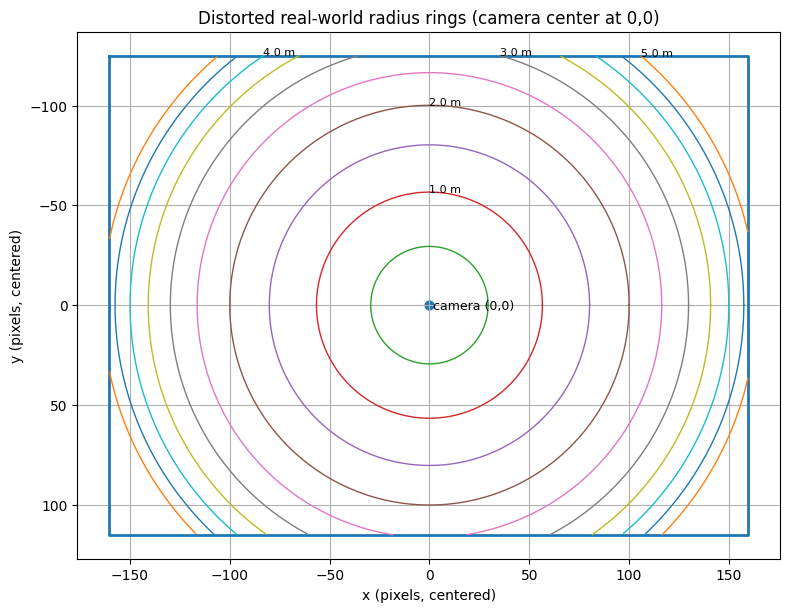

In [14]:
import math
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass

# ----------------------------
# Geometry
# ----------------------------
@dataclass
class Point:
    x: float
    y: float

# ----------------------------
# Calibration + fisheye (unchanged)
# ----------------------------
MAX_UNDISTORT_ITRS = 10

class CameraCalibrationParameters:
    def __init__(self, cx, cy, fx, fy, k0, k1, k2, k3):
        self.CX = cx
        self.CY = cy
        self.FX = fx
        self.FY = fy
        self.K0 = k0
        self.K1 = k1
        self.K2 = k2
        self.K3 = k3
        self.FX_INV = 1.0 / fx
        self.FY_INV = 1.0 / fy
        self.EPS2 = min(self.FX_INV, self.FY_INV) ** 2

class FisheyeInternal:
    @staticmethod
    def normalize(p, params):
        return Point((p.x - params.CX) * params.FX_INV,
                     (p.y - params.CY) * params.FY_INV)

    @staticmethod
    def denormalize(p, params):
        return Point(p.x * params.FX + params.CX,
                     p.y * params.FY + params.CY)

    @staticmethod
    def distort_normalized(p, params):
        r2 = p.x*p.x + p.y*p.y
        if r2 < params.EPS2:
            return p
        r = math.sqrt(r2)
        t = math.atan(r)
        t2 = t*t
        t3 = t2*t
        t5 = t3*t2
        t7 = t5*t2
        a = (t + params.K0*t3 + params.K1*t5 +
             params.K2*t7 + params.K3*t7*t2) / r
        return Point(p.x*a, p.y*a)

def distort(p, params):
    q = FisheyeInternal.normalize(p, params)
    q = FisheyeInternal.distort_normalized(q, params)
    return FisheyeInternal.denormalize(q, params)

def cm2pixel(p_cm, cam_height_cm, height_cm, params):
    p = Point(p_cm.x, p_cm.y)
    if height_cm != 0:
        factor = cam_height_cm / (cam_height_cm - height_cm)
        p.x *= factor
        p.y *= factor

    inv_h = 1.0 / cam_height_cm
    px = p.x * params.FX * inv_h + params.CX
    py = -p.y * params.FY * inv_h + params.CY
    return distort(Point(px, py), params)

# ----------------------------
# Visualization (camera center at 0,0)
# ----------------------------
def plot_distorted_rings_centered():
    IMG_W, IMG_H = 320, 240
    cam_height_cm = 250.0

    params = CameraCalibrationParameters(
        cx=320.7939205838952 / 2,
        cy=249.97515762182175 / 2,
        fx=298.00232438928845 / 2,
        fy=298.2902472606592 / 2,
        k0=-0.012590518225168094,
        k1=-0.010274419030002929,
        k2=0.03863572711209141,
        k3=-0.021344899238916176
    )

    radii_cm = np.arange(0, 501, 50)
    thetas = np.linspace(0, 2*math.pi, 720)

    plt.figure(figsize=(8, 8))

    # ---- image rectangle in centered coords ----
    xmin = -params.CX
    xmax = IMG_W - params.CX
    ymin = -params.CY
    ymax = IMG_H - params.CY

    plt.plot(
        [xmin, xmax, xmax, xmin, xmin],
        [ymin, ymin, ymax, ymax, ymin],
        linewidth=2
    )

    # camera center
    plt.scatter([0], [0], s=40)
    plt.text(2, 2, "camera (0,0)", fontsize=9)

    for R in radii_cm:
        xs, ys = [], []
        for th in thetas:
            wx = R * math.cos(th)
            wy = R * math.sin(th)
            ppx = cm2pixel(Point(wx, wy), cam_height_cm, 0.0, params)

            # shift so camera center = (0,0)
            x = ppx.x - params.CX
            y = ppx.y - params.CY

            if xmin <= x <= xmax and ymin <= y <= ymax:
                xs.append(x)
                ys.append(y)
            else:
                xs.append(np.nan)
                ys.append(np.nan)

        plt.plot(xs, ys, linewidth=1)

        if R % 100 == 0 and R > 0:
            idx = np.nanargmin(np.abs(np.array(xs)))
            plt.text(xs[idx], ys[idx], f"{R/100:.1f} m", fontsize=8)

    plt.gca().invert_yaxis()  # image coordinates
    plt.gca().set_aspect("equal", adjustable="box")
    plt.xlabel("x (pixels, centered)")
    plt.ylabel("y (pixels, centered)")
    plt.title("Distorted real-world radius rings (camera center at 0,0)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    plot_distorted_rings_centered()
